# RC3SI — Stage 02: Exploratory Data Analysis and Preprocessing

**Objective:** independently clean Parma 2023 sensor tables; inspect missing values and time gaps; visualize soil and environmental readings; align *past-only* environmental readings with zone-specific soil measurements; and create chronological train/validation/test partitions. **No ML training or performance claims in this stage.**

**How to use:** Open this notebook in Google Colab → Runtime → Run all → upload the same **RC3SI_Parma2023_Raw_Data_Only_v1.zip** from Stage 01. One major task per code cell. Download the output CSV/ZIP at the end. Default Colab CPU runtime is sufficient.

**Scientific scope:** One environment sensor is shared across three lines. Irrigation labels are **treatment assignments**, not plant-stress labels. Three 2023 lines are not independent replicates for any treatment. Data splits across time do not establish farm/line generalization.


## Cell 1 — Import libraries

In [1]:
from pathlib import Path
import io, zipfile, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
print('pandas:', pd.__version__)

pandas: 2.2.3


## Cell 2 — Upload the same original 2023 data-only ZIP

In [2]:
try:
    from google.colab import files
    uploaded = files.upload()
    assert len(uploaded) == 1, 'Upload exactly one dataset ZIP'
    zip_name, zip_bytes = next(iter(uploaded.items()))
except ImportError:
    zip_name = 'RC3SI_Parma2023_Raw_Data_Only_v1.zip'
    zip_bytes = Path(zip_name).read_bytes()
assert zip_name.lower().endswith('.zip')
print(f'Uploaded {zip_name} ({len(zip_bytes):,} bytes)')

Saving RC3SI_Parma2023_Raw_Data_Only_v1.zip to RC3SI_Parma2023_Raw_Data_Only_v1.zip
Uploaded RC3SI_Parma2023_Raw_Data_Only_v1.zip (920,149 bytes)


## Cell 3 — Load four raw tables (no preprocessing yet)

In [3]:
with zipfile.ZipFile(io.BytesIO(zip_bytes)) as zf:
    entries = {Path(x.filename).name: zf.read(x.filename) for x in zf.infolist() if not x.is_dir()}
required = {'stuard_environmental_data.csv','stuard_soil_data.csv','stuard_water_meter_data.csv','indicators.csv','README.TXT'}
assert required.issubset(entries), f'Missing: {required - entries.keys()}'
raw = {
    'environment': pd.read_csv(io.BytesIO(entries['stuard_environmental_data.csv']), low_memory=False),
    'soil': pd.read_csv(io.BytesIO(entries['stuard_soil_data.csv']), low_memory=False),
    'water': pd.read_csv(io.BytesIO(entries['stuard_water_meter_data.csv']), low_memory=False),
    'indicators': pd.read_csv(io.BytesIO(entries['indicators.csv']), low_memory=False),
}
display(pd.DataFrame([{'table':k,'raw_rows':len(v),'columns':len(v.columns)} for k,v in raw.items()]))

,table,raw_rows,columns
0,environment,10964,8
1,soil,32668,8
2,water,32649,5
3,indicators,77,8


## Cell 4 — Remove invalid timestamp/header rows and convert sensor measurements to numeric

This cell **does not** fill gaps, interpolate missing values or learn preprocessing parameters.

In [4]:
numeric_columns = {
    'environment': ['co2','humidity','pressure','temperature','battery'],
    'soil': ['electrical_conductivity','humidity','temperature','battery'],
    'water': ['current_volume'],
}
clean = {}
for name in ('environment','soil','water'):
    d = raw[name].copy()
    ts = pd.to_numeric(d['ts_generation'],errors='coerce')
    d = d.loc[ts.notna()].copy()
    d['timestamp'] = pd.to_datetime(pd.to_numeric(d['ts_generation']),unit='ms',utc=True,errors='coerce')
    d = d.dropna(subset=['timestamp'])
    if 'line' in d:
        d['line'] = pd.to_numeric(d['line'],errors='coerce')
        d = d.loc[d['line'].isin([1,2,3])].copy()
        d['line'] = d['line'].astype(int)
    for col in numeric_columns[name]:
        d[col] = pd.to_numeric(d[col],errors='coerce')
    clean[name] = d.sort_values('timestamp').reset_index(drop=True)
    print(name, 'valid rows:',len(d),'invalid/header rows removed:',len(raw[name])-len(d))

environment valid rows: 10964 invalid/header rows removed: 0
soil valid rows: 32666 invalid/header rows removed: 2
water valid rows: 32647 invalid/header rows removed: 2


## Cell 5 — Validate devices, line mapping and duplicate timestamps

In [5]:
for name,d in clean.items():
    keys = ['device_identifier','timestamp']
    duplicates = d.duplicated(keys).sum()
    print(f'{name}: duplicate device/timestamps = {duplicates}; distinct device IDs = {d.device_identifier.nunique()}')
    if name != 'environment':
        display(d[['line','device_identifier']].drop_duplicates().sort_values('line'))
assert 'line' not in clean['environment'].columns, 'Unexpected zone-specific environmental field'
assert clean['environment']['device_identifier'].nunique() == 1, 'Inspect environmental devices before proceeding'
assert all(clean[k].groupby('line').device_identifier.nunique().eq(1).all() for k in ('soil','water'))
print('Environmental features belong to ONE shared device; do not call them zone-specific.')

environment: duplicate device/timestamps = 0; distinct device IDs = 1
soil: duplicate device/timestamps = 0; distinct device IDs = 3


,line,device_identifier
0,1,91738f0250e567c5c673d2217596991d2eec0cc6da56ca...
96,2,9d5fe860849cee394ff52cd69a6d69642ea9f4756dac17...
120,3,0fa420b6626076658c3c1763550aee8149c2be5dba876a...


water: duplicate device/timestamps = 0; distinct device IDs = 3


,line,device_identifier
4,1,b11e71f8660d9d4afc220110d60e8856c38b6af3613b3e...
0,2,d17de8bc7da9be6528f0b5eb2a108138d2b885433890da...
1,3,c733ec31aff4605215b6a5fba926aaae8cf58133bb1f6d...


Environmental features belong to ONE shared device; do not call them zone-specific.


## Cell 6 — Check missing numeric values and plausible ranges (NO invented agronomic limits)

In [6]:
rows=[]
for name,d in clean.items():
    for col in numeric_columns[name]:
        s=d[col]
        rows.append({'table':name,'feature':col,'missing_pct':round(s.isna().mean()*100,2),
                     'minimum':s.min(),'median':s.median(),'maximum':s.max()})
quality=pd.DataFrame(rows)
display(quality)
print('Ranges are descriptive only: DO NOT treat extreme values as plant-stress thresholds.')

,table,feature,missing_pct,minimum,median,maximum
0,environment,co2,0.00,396.0,470.00,858.00
1,environment,humidity,0.00,18.0,57.25,97.00
2,environment,pressure,0.00,993.7,1010.50,1019.40
3,environment,temperature,0.00,10.1,26.10,43.70
4,environment,battery,99.32,100.0,100.00,100.00
5,soil,electrical_conductivity,0.00,0.0,295.00,1767.00
6,soil,humidity,0.00,0.0,23.41,56.81
7,soil,temperature,0.00,19.6,23.80,32.60
8,soil,battery,99.31,99.0,100.00,100.00
9,water,current_volume,0.00,0.0,15094.00,38280.00


Ranges are descriptive only: DO NOT treat extreme values as plant-stress thresholds.


## Cell 7 — Quantify sampling gaps and duplicate handling

We remove exact device–timestamp duplicates only **after** recording their count. If distinct values share one timestamp, the first record is retained for now and should be investigated.

In [7]:
gap_rows=[]
for name,d in clean.items():
    for dev,g in d.groupby('device_identifier'):
        unique=g.drop_duplicates(['device_identifier','timestamp'],keep='first').sort_values('timestamp')
        mins=unique['timestamp'].diff().dt.total_seconds().div(60).dropna()
        gap_rows.append({'table':name,'device_prefix':str(dev)[:12], 'observations':len(g),
                         'median_gap_min':mins.median(),'p95_gap_min':mins.quantile(.95),
                         'largest_gap_hr':mins.max()/60 if len(mins) else np.nan,
                         'gaps_over_3h':int((mins>180).sum())})
    clean[name]=d.drop_duplicates(['device_identifier','timestamp'],keep='first').copy().sort_values('timestamp').reset_index(drop=True)
gaps=pd.DataFrame(gap_rows)
display(gaps)

,table,device_prefix,observations,median_gap_min,p95_gap_min,largest_gap_hr,gaps_over_3h
0,environment,abc0d16aaf15,10964,9.999550,10.000367,6.795270,1
1,soil,0fa420b66260,10838,10.022700,10.023017,0.501140,0
2,soil,91738f0250e5,10966,10.022767,10.023167,0.501139,0
3,soil,9d5fe860849c,10862,10.022733,10.023083,0.501139,0
4,water,b11e71f8660d,10800,10.001433,10.016617,0.667112,0
5,water,c733ec31aff4,10941,10.000967,10.016183,0.499869,0
6,water,d17de8bc7da9,10906,10.001067,10.016333,0.665871,0


## Cell 8 — Descriptive statistics for soil sensors by line

In [8]:
treatments={1:'100% reference',2:'60% intermediate',3:'30% reduced'}
soil_stats=clean['soil'].groupby('line')[['humidity','temperature','electrical_conductivity']].agg(['count','mean','median','std','min','max']).round(2)
display(soil_stats)
print('Line identity and treatment are confounded: differences cannot be attributed to treatment alone.')

humidity                                  temperature                \
        count   mean median   std   min    max       count   mean median   
line                                                                       
1       10966  25.91  25.17  3.94  0.00  40.71       10966  23.38   23.2   
2       10862  25.49  22.41  8.08  2.02  53.56       10862  24.20   23.9   
3       10838  25.95  21.75  9.61  0.00  56.81       10838  24.36   24.2   

                       electrical_conductivity                             \
       std   min   max                   count    mean median     std min   
line                                                                        
1     1.81  19.6  29.0                   10966  335.15  344.0  136.42   0   
2     2.32  19.7  32.6                   10862  363.04  248.0  272.57  56   
3     1.87  20.5  29.7                   10838  425.43  278.0  360.17   0   

            
       max  
line        
1     1071  
2     1443  
3     1767

Line identity and treatment are confounded: differences cannot be attributed to treatment alone.


## Cell 9 — Visualize observed soil-humidity trends (3-hour visualization only)

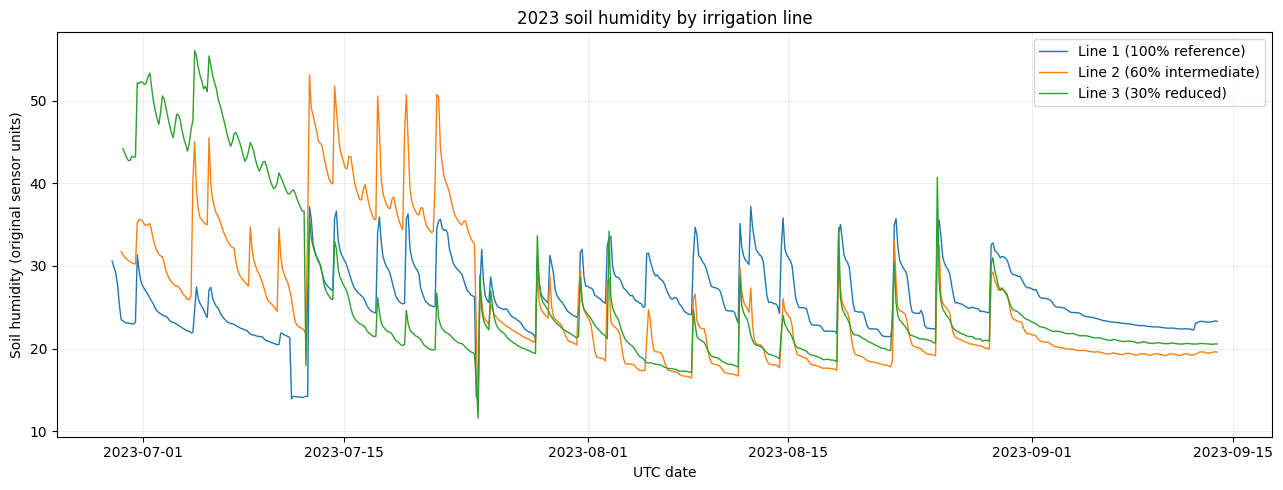

In [9]:
fig,ax=plt.subplots(figsize=(13,5))
for line,g in clean['soil'].groupby('line'):
    series=g.set_index('timestamp')['humidity'].resample('3h').median()
    ax.plot(series.index,series,label=f'Line {line} ({treatments[line]})',linewidth=1)
ax.set(title='2023 soil humidity by irrigation line',xlabel='UTC date',ylabel='Soil humidity (original sensor units)')
ax.legend();ax.grid(alpha=.2);plt.tight_layout();plt.show()

## Cell 10 — Visualize the single shared environmental stream

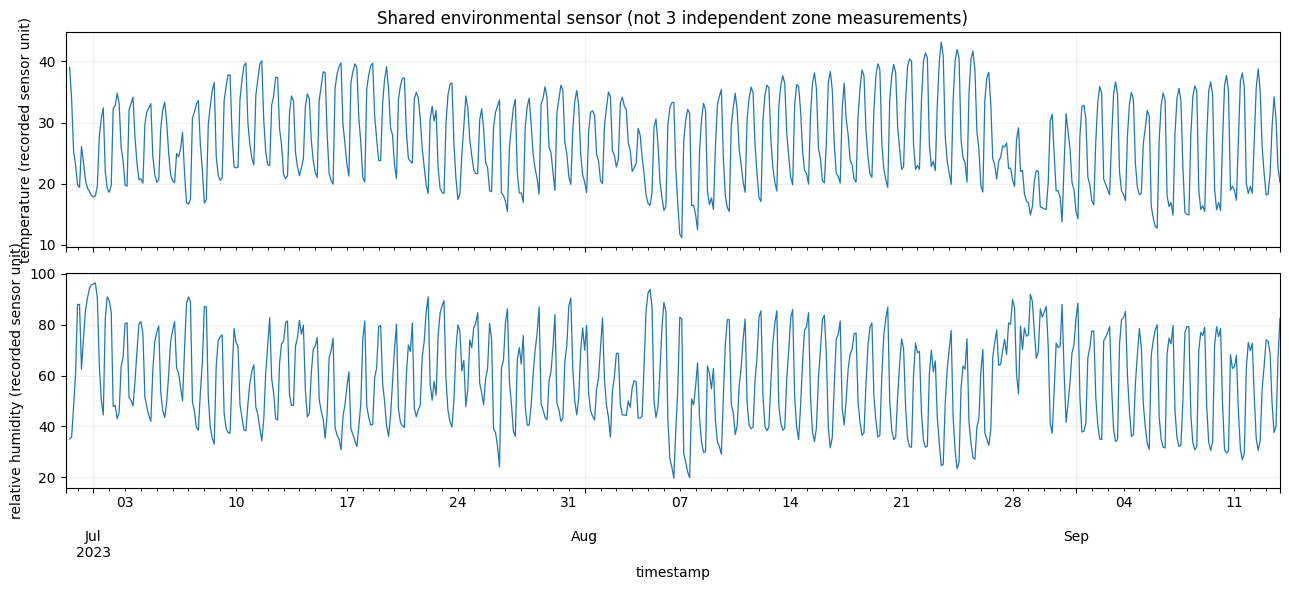

In [10]:
env=clean['environment'].set_index('timestamp')
fig,axs=plt.subplots(2,1,figsize=(13,6),sharex=True)
for ax,col,unit in zip(axs,['temperature','humidity'],['temperature (recorded sensor unit)','relative humidity (recorded sensor unit)']):
    env[col].resample('3h').median().plot(ax=ax,linewidth=.9)
    ax.set_ylabel(unit);ax.grid(alpha=.2)
axs[0].set_title('Shared environmental sensor (not 3 independent zone measurements)')
plt.tight_layout();plt.show()

## Cell 11 — Compare timestamps and daily coverage

The coverage plot displays counts only; it does not infer missing readings.

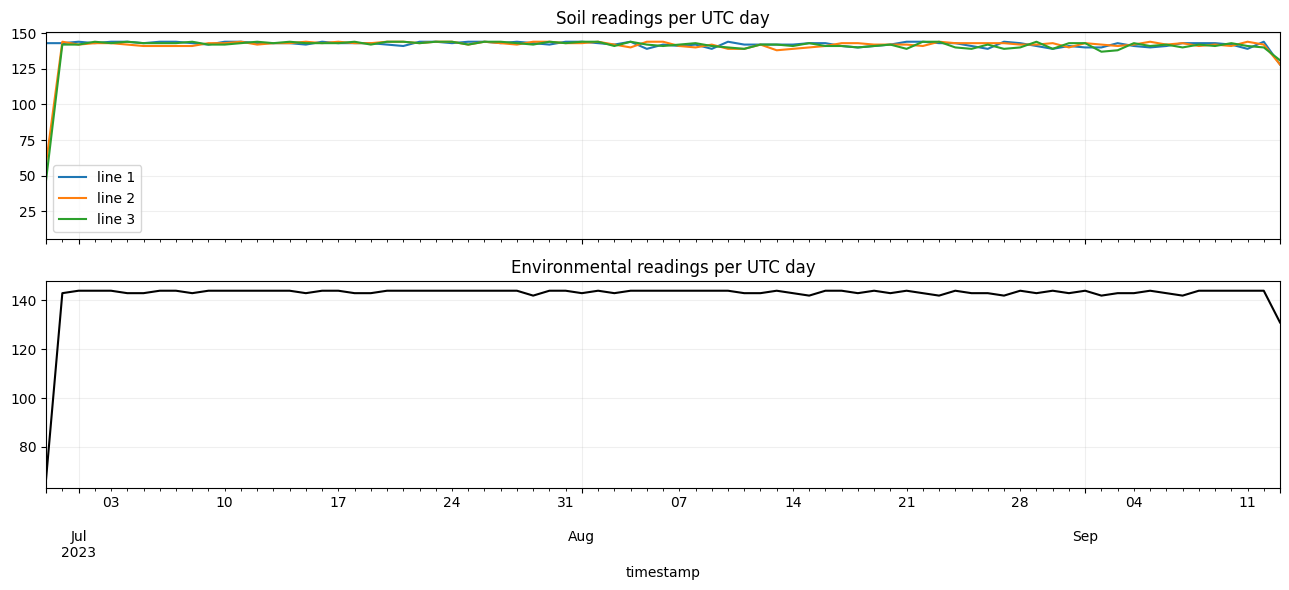

In [11]:
fig,axs=plt.subplots(2,1,figsize=(13,6),sharex=True)
for line,g in clean['soil'].groupby('line'):
    g.set_index('timestamp')['humidity'].resample('1D').count().plot(ax=axs[0],label=f'line {line}')
clean['environment'].set_index('timestamp')['temperature'].resample('1D').count().plot(ax=axs[1],color='black')
axs[0].set_title('Soil readings per UTC day');axs[0].legend();axs[0].grid(alpha=.2)
axs[1].set_title('Environmental readings per UTC day');axs[1].grid(alpha=.2)
plt.tight_layout();plt.show()

## Cell 12 — Build *past-only* soil snapshots for all lines (hourly)

For each 1-hour interval we use the **latest observed soil sample within that hour**, timestamped at interval end. A future sample is never substituted for an earlier time. Empty hours stay missing and are dropped in this initial experiment.

In [12]:
soil_features=['humidity','temperature','electrical_conductivity']
soil_hourly=[]
for line,g in clean['soil'].groupby('line'):
    hourly=(g.set_index('timestamp')[soil_features]
            .resample('1h',label='right',closed='right').last()
            .dropna(subset=['humidity']))
    hourly['line']=line
    soil_hourly.append(hourly.reset_index())
soil_hourly=pd.concat(soil_hourly,ignore_index=True).sort_values(['timestamp','line'])
soil_hourly=soil_hourly.rename(columns={c:'soil_'+c for c in soil_features})
print('Soil hourly rows:',len(soil_hourly))
display(soil_hourly.head())

Soil hourly rows: 5510


,timestamp,soil_humidity,soil_temperature,soil_electrical_conductivity,line
0,2023-06-28 23:00:00+00:00,30.57,24.6,372,1
1,2023-06-29 00:00:00+00:00,30.30,24.4,364,1
2,2023-06-29 01:00:00+00:00,30.01,24.2,361,1
3,2023-06-29 02:00:00+00:00,29.73,24.0,359,1
4,2023-06-29 03:00:00+00:00,29.60,23.8,357,1


## Cell 13 — Align only historical environmental context (as-of backward join)

A record is accepted only if the latest environmental sample was observed **at or before** the soil-hour timestamp and was at most **90 minutes old**. Unlike a nearest-neighbor join, this cannot pick observations from the future.

In [13]:
env_features=['co2','humidity','pressure','temperature']
env_for_join=clean['environment'][['timestamp']+env_features].copy().rename(columns={c:'env_'+c for c in env_features})
env_for_join=env_for_join.rename(columns={'timestamp':'environment_observed_at'}).sort_values('environment_observed_at')
joined=pd.merge_asof(soil_hourly.sort_values('timestamp'),env_for_join,
                     left_on='timestamp',right_on='environment_observed_at',
                     direction='backward',tolerance=pd.Timedelta('90min'))
joined['env_age_minutes']=(joined['timestamp']-joined['environment_observed_at']).dt.total_seconds()/60
assert joined['env_age_minutes'].dropna().ge(0).all()
assert joined['env_age_minutes'].dropna().le(90).all()
print('With environmental match:',joined.environment_observed_at.notna().sum(), '/',len(joined))
display(joined.head())

With environmental match: 5496 / 5510


,timestamp,soil_humidity,soil_temperature,soil_electrical_conductivity,line,environment_observed_at,env_co2,env_humidity,env_pressure,env_temperature,env_age_minutes
0,2023-06-28 23:00:00+00:00,30.57,24.6,372,1,NaT,NaN,NaN,NaN,NaN,NaN
1,2023-06-29 00:00:00+00:00,30.30,24.4,364,1,NaT,NaN,NaN,NaN,NaN,NaN
2,2023-06-29 01:00:00+00:00,30.01,24.2,361,1,NaT,NaN,NaN,NaN,NaN,NaN
3,2023-06-29 02:00:00+00:00,29.73,24.0,359,1,NaT,NaN,NaN,NaN,NaN,NaN
4,2023-06-29 03:00:00+00:00,29.60,23.8,357,1,NaT,NaN,NaN,NaN,NaN,NaN


## Cell 14 — Inspect alignment coverage and retain explicitly complete rows

No scaling or imputation is performed yet. Rows missing required sensor features are excluded from the first supervised experiment; we record exactly how many are excluded.

In [14]:
required_features=['soil_humidity','soil_temperature','soil_electrical_conductivity',
                   'env_co2','env_humidity','env_pressure','env_temperature']
coverage=joined[required_features].isna().mean().mul(100).sort_values(ascending=False).rename('missing_pct')
display(coverage.to_frame())
model_table=joined.dropna(subset=required_features).copy().sort_values(['timestamp','line']).reset_index(drop=True)
model_table['treatment_percent']=model_table.line.map({1:100,2:60,3:30})
print('Complete hourly samples:',len(model_table), 'of',len(joined))
print('Counts by line:', model_table.line.value_counts().sort_index().to_dict())

,missing_pct
env_pressure,0.254083
env_humidity,0.254083
env_co2,0.254083
env_temperature,0.254083
soil_electrical_conductivity,0.000000
soil_humidity,0.000000
soil_temperature,0.000000


Complete hourly samples: 5496 of 5510
Counts by line: {1: 1834, 2: 1832, 3: 1830}


## Cell 15 — Make chronological train/validation/test partitions with a 24-hour embargo

The thresholds below are selected by time quantiles across **unique UTC dates**, not by looking at features, model results or class proportions. There is an excluded 24-hour gap between consecutive partitions. Stage 04 must fit scalers/feature selectors/models on TRAIN ONLY. **This is a within-season split on the SAME physical lines, not an unseen-line or unseen-farm test.**

In [15]:
days=pd.Index(model_table.timestamp.dt.floor('D').drop_duplicates().sort_values())
assert len(days)>=20,'Too few unique days for these splits'
t1=days[int(len(days)*.60)]
t2=days[int(len(days)*.80)]
embargo=pd.Timedelta('24h')
model_table['split']='embargo_excluded'
model_table.loc[model_table.timestamp < t1,'split']='train'
model_table.loc[(model_table.timestamp >= t1+embargo)&(model_table.timestamp < t2),'split']='validation'
model_table.loc[model_table.timestamp >= t2+embargo,'split']='test'
print('Train cutoff:',t1,'Validation cutoff:',t2,'Embargo:',embargo)
display(pd.crosstab(model_table['split'], model_table['line']))
assert set(['train','validation','test']).issubset(set(model_table['split']))
assert model_table.loc[model_table.split=='train','timestamp'].max() < model_table.loc[model_table.split=='validation','timestamp'].min()
assert model_table.loc[model_table.split=='validation','timestamp'].max() < model_table.loc[model_table.split=='test','timestamp'].min()

Train cutoff: 2023-08-14 00:00:00+00:00 Validation cutoff: 2023-08-29 00:00:00+00:00 Embargo: 1 days 00:00:00


line,1,2,3
split,,,
embargo_excluded,48,48,48
test,359,359,359
train,1091,1089,1087
validation,336,336,336


## Cell 16 — Visualize the chronological partition boundaries

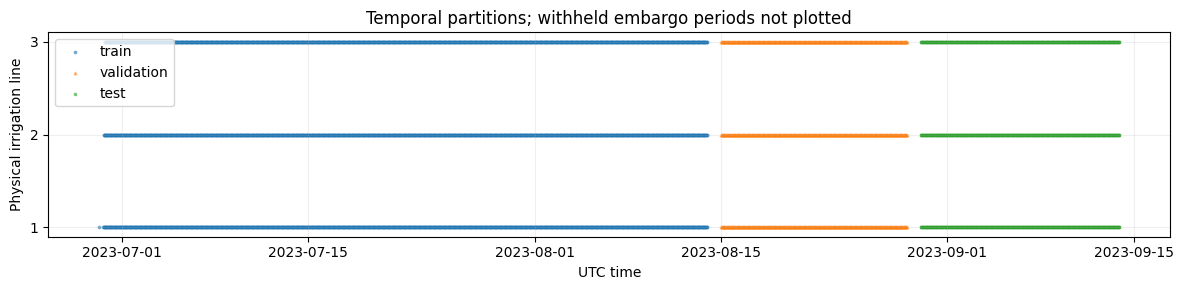

In [16]:
fig,ax=plt.subplots(figsize=(12,3))
for split,style in [('train','o'),('validation','^'),('test','s')]:
    dd=model_table.loc[model_table.split==split]
    ax.scatter(dd.timestamp,dd.line,s=3,marker=style,label=split,alpha=.5)
ax.set(yticks=[1,2,3],ylabel='Physical irrigation line',xlabel='UTC time',title='Temporal partitions; withheld embargo periods not plotted')
ax.legend();ax.grid(alpha=.2);plt.tight_layout();plt.show()

## Cell 17 — Export Stage 02 cleaned/merged CSV, QA summaries and split metadata

In [17]:
out=Path('rc3si_stage02_outputs');out.mkdir(exist_ok=True)
model_table.to_csv(out/'parma2023_hourly_with_splits.csv',index=False)
quality.to_csv(out/'missing_and_ranges.csv',index=False)
gaps.to_csv(out/'sampling_gaps.csv',index=False)
metadata={'dataset':'Parma 2023 (Mendeley 35wh56287y/2), data ZIP verified by user',
          'join':'hourly observed soil data + backward asof latest env up to 90 minutes old',
          'features':required_features,
          'train_before_utc':t1.isoformat(),'validation_from_utc':(t1+embargo).isoformat(),
          'validation_before_utc':t2.isoformat(),'test_from_utc':(t2+embargo).isoformat(),
          'embargo_hours':24,'class_semantics':'irrigation assignments, not physiological stress',
          'limitations':['one farm and year','one physical line per treatment','shared environmental device',
                         'timestamps/windows are NOT independent treatment replicates','no causal inference']}
(out/'stage02_metadata.json').write_text(json.dumps(metadata,indent=2))
with zipfile.ZipFile('RC3SI_Stage02_Outputs_v1.zip','w',zipfile.ZIP_DEFLATED) as z:
    for f in out.iterdir():z.write(f,arcname=f.name)
print('Saved RC3SI_Stage02_Outputs_v1.zip — download through Colab left-side Files panel.')
display(model_table.groupby(['split','line']).size().rename('hourly_samples').to_frame())

Saved RC3SI_Stage02_Outputs_v1.zip — download through Colab left-side Files panel.


hourly_samples
split            line                
embargo_excluded 1                 48
                 2                 48
                 3                 48
test             1                359
                 2                359
                 3                359
train            1               1091
                 2               1089
                 3               1087
validation       1                336
                 2                336
                 3                336

## Checkpoint before Stage 03

Please share your executed notebook or **the output ZIP**. We will verify the missing data, join coverage and split counts before engineering time-window features or training any model. **Do not report accuracy, ROC-AUC, physiological stress or early-warning performance at this stage.**

In later stages, the initial classifier will compare 100% vs 30% *treatment-associated patterns*. We will fit transformations within train, select models via validation, use test once, and explain line/treatment confounding. The 60% line should not be casually labeled as a verified physiological intermediate stress class.